# CS179 Homework 5 
### Due: Wednesday, May 27 2026 (11:59 PM)

---
## Instructions

This homework contains quite a lot of starter code and templates, so it is being issued in past years' format: as a jupyter notebook that you can complete and convert to PDF for upload to GradeScope.  Unlike previous homeworks, this will require that you assign page numbers to each problem in the assignment.

Please submit a **single PDF file** that contains everything to Gradescope. This includes any text you wish to include to describe your results, the complete code snippets of how you attempted each problem, any figures that were generated, and scans of any work on paper that you wish to include. It is important that you include enough detail that we know how you solved the problem, since otherwise we will be unable to grade it.

You are encouraged to use this starter Jupyter notebooks to complete your assignment and to write your report. This will help you not only ensure that all of the code for the solutions is included, but also will provide an easy way to export your results to a PDF file (for example, doing *print preview* and *printing to pdf*). I recommend liberal use of Markdown cells to create headers for each problem and sub-problem, explaining your implementation/answers, and including any mathematical equations. For parts of the homework you do on paper, scan it in such that it is legible (there are a number of free Android/iOS scanning apps, if you do not have access to a scanner), and include it as an image in the Jupyter notebook.

**Double check that all of your answers are legible on Gradescope, e.g. make sure any figures or text you have written does not get cut off.**

If you have any questions/concerns about using Jupyter notebooks, ask us on EdD. If you decide not to use Jupyter notebooks, but go with Microsoft Word or LaTeX to create your PDF file, make sure that all of the answers can be generated from the code snippets included in the document.

### Summary of Assignment: 100 total points
- Part 1: Loading the Data (10 points)
- Part 2: Model Setup (10 points)
- Part 3: Variational Posterior (30 points)
  * **Note**: it is possible to use pre-trained results to skip Part 3, at a penalty.
- Part 4: Visualizing the Posterior (20 points)
- Part 5: Evaluating Predictions (25 points)
- Statement of Collaboration (5 points)

In [81]:
import matplotlib.pyplot as plt

import pygms as gm
import numpy as np
import torch
import random

import requests                                      # reading data
from io import StringIO
import time

import pyro
import pyro.infer
import pyro.optim
import pyro.distributions as dist
import pyro.poutine as poutine

from IPython.display import display, clear_output  # for iterative plotting

seed = 1234321
provided_results_seed = 99199
random.seed(seed)
pyro.set_rng_seed(seed)

<div>
    <img src="data:image/svg+xml,%3C%3Fxml%20version%3D%221.0%22%20encoding%3D%22UTF-8%22%20standalone%3D%22no%22%3F%3E%0A%3C%21DOCTYPE%20svg%20PUBLIC%20%22-//W3C//DTD%20SVG%201.1//EN%22%20%22http%3A//www.w3.org/Graphics/SVG/1.1/DTD/svg11.dtd%22%3E%0A%3Csvg%20stroke-miterlimit%3D%2210%22%20style%3D%22fill-rule%3Anonzero%3Bclip-rule%3Aevenodd%3Bstroke-linecap%3Around%3Bstroke-linejoin%3Around%3B%22%20version%3D%221.1%22%20viewBox%3D%220%200%20288%2072%22%20xml%3Aspace%3D%22preserve%22%20xmlns%3D%22http%3A//www.w3.org/2000/svg%22%20xmlns%3Axlink%3D%22http%3A//www.w3.org/1999/xlink%22%3E%0A%3Cdefs/%3E%0A%3Cg%20id%3D%22Layer-1%22%3E%0A%3Cpath%20d%3D%22M34.042%2035.8741C45.8469%2023.244%2031.1794%2022.6473%2024.2857%2024.1167C17.3921%2025.5861-0.960215%2033.2987%206.07817%2043.4256C13.1166%2053.5525%2023.0237%2056.9377%2052.2446%2053.4091C81.4656%2049.8804%2097.2436%2032.811%20122.962%2029.3111C148.681%2025.8112%20155.118%2039.4093%20155.118%2039.4093%22%20fill%3D%22none%22%20opacity%3D%221%22%20stroke%3D%22%23000000%22%20stroke-linecap%3D%22butt%22%20stroke-linejoin%3D%22round%22%20stroke-width%3D%223%22/%3E%0A%3Cpath%20d%3D%22M254.053%2040.6889C242.328%2053.1071%20256.999%2053.6247%20263.883%2052.1549C270.768%2050.685%20289.071%2043.0512%20281.969%2033.1691C274.868%2023.287%20264.94%2020.0179%20235.741%2023.6051C206.543%2027.1922%20190.872%2043.9744%20165.176%2047.5176C139.48%2051.0607%20132.957%2037.7776%20132.957%2037.7776%22%20fill%3D%22none%22%20opacity%3D%221%22%20stroke%3D%22%23000000%22%20stroke-linecap%3D%22butt%22%20stroke-linejoin%3D%22round%22%20stroke-width%3D%223%22/%3E%0A%3C/g%3E%0A%3C/svg%3E%0A" width="200"/>
</div>

In this homework, we will Pyro's stochastic variational inference (SVI) procedure 
to explore a simple model for collaborative
filtering, specifically, to predict movie ratings on a (very small) subset of the MovieLens dataset.

For more examples of variational inference in Pyro, please see the course demos on Pyro (VI) and
Bayesian linear regression.

### Part 1: Loading the Data
First, load the data.  The data have been split into training (``cs179-hw5-train.csv``) and test (``cs179-hw5-test.csv``) rating sets, a good practice when evaluating predictive models. In this case, both files contain
an $n \times m$ array, where $n$ is the number of users in the dataset (rows) and $m$ the number of movies (columns).  The first line of each file is a "comment" line (preceded by ``#``) that lists the titles of the movies in our dataset.  The remaining lines are comma-separated integers between zero and nine, or ``NaN``(not-a-number), indicating the value is not observed in this file.

In [82]:
# Load the features and labels from an online text file
tr_url = 'https://ics.uci.edu/~ihler/classes/cs179/data/mlens-small-train.csv'
te_url = 'https://ics.uci.edu/~ihler/classes/cs179/data/mlens-small-test.csv'

with requests.get(tr_url, verify=False) as link: titles = StringIO(link.text).readline()[2:].strip().split(',')
with requests.get(tr_url, verify=False) as link: Xtr = np.loadtxt(StringIO(link.text),delimiter=',')
with requests.get(te_url, verify=False) as link: Xte = np.loadtxt(StringIO(link.text),delimiter=',')

# It's helpful to have a list of "short" names for display purposes:
short = {0:'ToyStory',1:'Aladdin ',2:'Cars    ',3:'Potter2 ',4:'Potter3 ',5:'DieHard ',
         6:'Aliens  ',7:"Gremlins",8:"LWomen  ",9:"BoysSide"}

C:\Users\dustp\anaconda3\envs\cs179\Lib\site-packages\urllib3\connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'ics.uci.edu'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
C:\Users\dustp\anaconda3\envs\cs179\Lib\site-packages\urllib3\connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'ics.uci.edu'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
C:\Users\dustp\anaconda3\envs\cs179\Lib\site-packages\urllib3\connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'ics.uci.edu'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(


**(a)**
* How many ratings (non-NaN values) are in your training set?  In the test set?  How many are missing from both?

In [83]:
n, m = Xtr.shape
tr_count = int(np.sum(~np.isnan(Xtr)))
te_count = int(np.sum(~np.isnan(Xte)))
missing  = int(np.sum(np.isnan(Xtr) & np.isnan(Xte)))
print(f"Train ratings: {tr_count}")
print(f"Test ratings:  {te_count}")
print(f"Missing from both: {missing}")
print(f"Total cells: {n*m}")

Train ratings: 739
Test ratings:  207
Missing from both: 54
Total cells: 1000


As a simple first step, let's center the ratings by subtracting their mean.  (Most users rate most of the movies they rate as better than average, so this will try to take care of this positive bias.)  We'll also move the ratings into a more useful data structure:

In [84]:
train_avg = np.nanmean(Xtr)       # use "nanmean" to take the mean, ignoring "NaN" values
Xtr -= train_avg
Xte -= train_avg

ratings,rtest = {},{}                   # Let's store the ratings as a dict: (m,u) -> r_{mu}
for i in range(n):
    for j in range(m):
        r = Xtr[i,j]
        if not np.isnan(r): ratings[(i,j)] = np.round(r,2)   # just to make printing nicer
        if not np.isnan(Xte[i,j]): rtest[(i,j)] = Xte[i,j]   # save test data in dict also

**(b)**
* Pick your favorite movie in the list (say which one) and plot a histogram of its (zero-centered) ratings

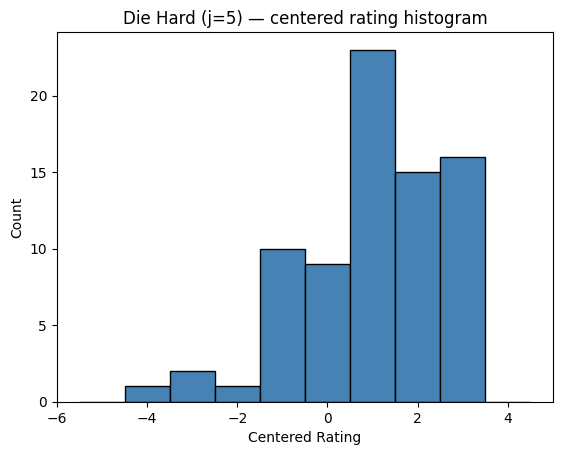

In [85]:
# Favorite movie: Die Hard (j=5)
diehard = Xtr[:,5] - np.nanmean(Xtr)  # already centered if you ran In[6]
# Actually Xtr is already centered after In[6], so just:
vals = Xtr[:,5]
vals = vals[~np.isnan(vals)]
plt.hist(vals, bins=np.arange(-5,6)-0.5, edgecolor='k', color='steelblue')
plt.xlabel('Centered Rating'); plt.ylabel('Count')
plt.title('Die Hard (j=5) — centered rating histogram')
plt.show()

**(c)**:
* For that movie and one other (your choice; be sure to say which two), plot a scatterplot of the rating pairs for those two movies:

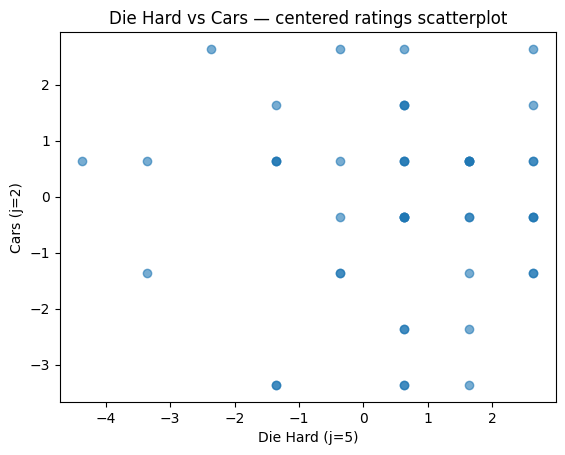

In [86]:
# Die Hard (j=5) vs Cars (j=2)
dh = Xtr[:,5]
cars = Xtr[:,2]
mask = ~np.isnan(dh) & ~np.isnan(cars)
plt.scatter(dh[mask], cars[mask], alpha=0.6)
plt.xlabel('Die Hard (j=5)')
plt.ylabel('Cars (j=2)')
plt.title('Die Hard vs Cars — centered ratings scatterplot')
plt.show()

<div>
    <img src="data:image/svg+xml,%3C%3Fxml%20version%3D%221.0%22%20encoding%3D%22UTF-8%22%20standalone%3D%22no%22%3F%3E%0A%3C%21DOCTYPE%20svg%20PUBLIC%20%22-//W3C//DTD%20SVG%201.1//EN%22%20%22http%3A//www.w3.org/Graphics/SVG/1.1/DTD/svg11.dtd%22%3E%0A%3Csvg%20stroke-miterlimit%3D%2210%22%20style%3D%22fill-rule%3Anonzero%3Bclip-rule%3Aevenodd%3Bstroke-linecap%3Around%3Bstroke-linejoin%3Around%3B%22%20version%3D%221.1%22%20viewBox%3D%220%200%20288%2072%22%20xml%3Aspace%3D%22preserve%22%20xmlns%3D%22http%3A//www.w3.org/2000/svg%22%20xmlns%3Axlink%3D%22http%3A//www.w3.org/1999/xlink%22%3E%0A%3Cdefs/%3E%0A%3Cg%20id%3D%22Layer-1%22%3E%0A%3Cpath%20d%3D%22M34.042%2035.8741C45.8469%2023.244%2031.1794%2022.6473%2024.2857%2024.1167C17.3921%2025.5861-0.960215%2033.2987%206.07817%2043.4256C13.1166%2053.5525%2023.0237%2056.9377%2052.2446%2053.4091C81.4656%2049.8804%2097.2436%2032.811%20122.962%2029.3111C148.681%2025.8112%20155.118%2039.4093%20155.118%2039.4093%22%20fill%3D%22none%22%20opacity%3D%221%22%20stroke%3D%22%23000000%22%20stroke-linecap%3D%22butt%22%20stroke-linejoin%3D%22round%22%20stroke-width%3D%223%22/%3E%0A%3Cpath%20d%3D%22M254.053%2040.6889C242.328%2053.1071%20256.999%2053.6247%20263.883%2052.1549C270.768%2050.685%20289.071%2043.0512%20281.969%2033.1691C274.868%2023.287%20264.94%2020.0179%20235.741%2023.6051C206.543%2027.1922%20190.872%2043.9744%20165.176%2047.5176C139.48%2051.0607%20132.957%2037.7776%20132.957%2037.7776%22%20fill%3D%22none%22%20opacity%3D%221%22%20stroke%3D%22%23000000%22%20stroke-linecap%3D%22butt%22%20stroke-linejoin%3D%22round%22%20stroke-width%3D%223%22/%3E%0A%3C/g%3E%0A%3C/svg%3E%0A" width="200"/>
</div>

### Part 2: Model Setup

We will use a Bayesian variant of the SVD low-rank decomposition, or latent space reprsentation,
for collaborative filtering described in CS178.  If you haven't seen this and want to read more
about it,
you can see these data evaluated using non-probabilistic unsupervised learning in the CS178
course notes:

https://canvas.eee.uci.edu/courses/31018/files/folder/Notes

parts 10 (clustering) and 11 (latent space models).

Our model associates a $K$-dimensional "position" with each user $i$ and each movie $j$,
denoted $U_i$ and $V_j$, respectively.  Then, the degree to which user $i$ likes movie $j$
is a function of their dot product, $U_i \cdot V^T_j = \sum_k U_{ik} V_{jk}$.
This will try to place similarly rated movies in a similar direction from the origin,
with users that like those movies placed in the same direction, so that the dot product
will be large.

A small modification helps the model in practice.  Since some users are more positive than others,
and some movies are more widely acknowledged as good or bad, we may want to instead predict 
"relative" preference.  We can do this by adding an extra bias term $\nu_i$, $\mu_j$ for each user $i$ and movie $j$.

We place simple Gaussian priors on all the unknown values: the vectors $\nu$, $\mu$ and the entries in both
matrices $U,V$.  
If we have only a few ratings, we would prefer to explain them using personal preference rather than the bias terms, so we give the $\nu$, $\mu$ priors with smaller variance (we expect them to be closer to zero, given the same amount of evidence:
$$\nu_i, \mu_j \sim {\cal N}(0, .1)$$
and the $U$, $V$ entries priors with higher variance:
$$U_{ik}, V_{jk} \sim {\cal N}(0, 1)$$

Then, we express the probability of our observations as Gaussian with
a fixed standard deviation:
$$ r_{nm} \sim {\cal N}\big( R\,;\, \nu_i + \mu_j + U_i\cdot V_j^T \ ,\ (0.5)^2 \,\big).$$

This model is encapsulated in the following Pyro function:

In [87]:
pyro.get_param_store().clear()   # clear any defined parameters in case we're re-running

def to_np(A): return np.vstack([a.detach().numpy() for a in A if a is not None])

def model(ratings,n,m,k,S=None):
    U,nu, V,mu = [None]*n,[None]*n, [None]*m,[None]*m
    ulist = pyro.plate("users",n,subsample_size=n if S is None else min(n,S))
    mlist = pyro.plate("movies",m,subsample_size=m if S is None else min(m,S))
    for i in ulist: 
        nu[i]  = pyro.sample(f'nu{i}',dist.Normal(torch.zeros(1), .1*torch.eye(1)))
        U[i]  = pyro.sample(f'U{i}',dist.MultivariateNormal(torch.zeros(k), torch.eye(k)))
    for j in mlist: 
        mu[j] = pyro.sample(f'mu{j}',dist.Normal(torch.zeros(1), .1*torch.eye(1)))
        V[j] = pyro.sample(f'V{j}',dist.MultivariateNormal(torch.zeros(k), torch.eye(k)))
    sig = 0.25
    for i in ulist:
        for j in mlist:
            if (i,j) in ratings:
                pyro.sample(f'R{i}{j}',dist.Normal(nu[i]+mu[j]+U[i]@V[j],sig), obs=torch.tensor(ratings[(i,j)]))
    if S is None:       # useful return if you want to access samples from the prior
        return to_np(nu),to_np(mu),to_np(U),to_np(V)

Here we use Pyro's ``plate`` for indexing, which informs Pyro that the indexed elements are conditionally independent from one another;
see the generation of the theta parameters in

http://sli.ics.uci.edu/extras/cs179/Demo%20-%20Bayesian%20Linear%20Regression%20(Pyro).html

and the generation of the i.i.d. data points in 

https://sli.ics.uci.edu/extras/cs179/Demo-EM-Pyro.html

for other examples.  We also use `subsample_size` to speed up the optimization, using only part of the data at a time.

**Note:** This example is similar to the latent variable model you used for skill in HW5.  In particular, you have a latent variable that "explains" the observations; in the skill model, each user had a scalar skill score, while in this model, each user has both a scalar (their bias $\nu$) and a vector (their preferences $U$).  Then, we observe these values only indirectly -- for skill, a win tells us something about the players' relative skill values, while here, a high or low rating tells us about the user's preferences in combination with the characteristics of that movie, $\mu$ and $V$.

We don't really need a return value, but it's sometimes handy to have one.  Here, we return (as numpy arrays) the random variables that make up our rating predictions.  Calling ``model(...)`` will then return a (prior) sample from $p(\nu,\mu,U,V)$, which we can use to sample our model's prior beliefs about the ratings matrix $X$:

In [88]:
nu,mu,U,V = model(ratings,n,m,2)   # draws one sample from the prior (ignores "ratings" when sampling)

(U@V.T+nu+mu.T)[:4,:5].round(2)    # construct that sample's R values & display part of them:

array([[ 1.24,  0.95,  0.2 ,  0.11, -0.12],
       [ 2.52,  2.1 ,  0.69,  0.48,  0.1 ],
       [ 1.99,  2.5 ,  1.8 , -0.1 , -1.33],
       [-0.29,  1.19,  2.36, -0.52, -2.07]], dtype=float32)

To get a collection of samples, we can just stack them up in NumPy:

In [89]:
prior_samples = np.stack( tuple(U@V.T+nu+mu.T for s in range(100) for nu,mu,U,V in [model({},n,m,2)]) ,axis=-1)

**(a)**: Use your data and these samples from the prior distribution to:

* Plot the values in the training data for Die Hard ($i=5$) versus Aliens ($i=6$).  
  Here, your plot should consist of $n$ points (one for each user), with position (x,y) where x is that user's rating of Die Hard, and y is that user's rating of Aliens.
  Since the actual rating values are integer, add a bit of random noise to the values when you plot, e.g., plot

  ``Xtr[:,5]+.7*np.random.rand(n)``
  
  for the Die Hard ratings, rather than the true ``Xtr`` values (this will make it clearer where there are many samples).
  
* Add to your plot the average rating (over samples) for each user on those two movies.  Again, you should add $n$ more points, similar to your plot of the training data, but taken from your prior distribution's samples. Color the points to distinguish them from your training data.

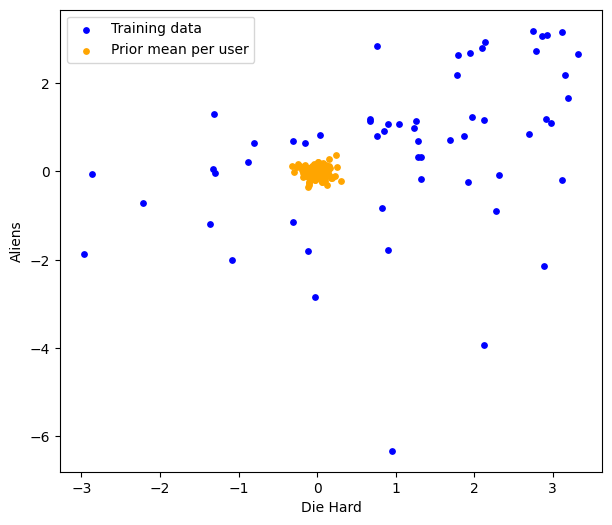

In [104]:
np.random.seed(seed)
fig, ax = plt.subplots(figsize=(7,6))
ax.scatter(Xtr[:,5] + 0.7*np.random.rand(n), Xtr[:,6] + 0.7*np.random.rand(n), color='blue', label='Training data', s=15)
prior_dh, prior_al = prior_samples[:,5,:].mean(axis=1), prior_samples[:,6,:].mean(axis=1)
ax.scatter(prior_dh, prior_al, color='orange', label='Prior mean per user', s=15)
ax.set_xlabel('Die Hard'); ax.set_ylabel('Aliens'); ax.legend(); plt.show()

**(b)**: **Then,**
* Comment briefly on the differences between the prior samples and the data.

The prior samples (orange) are close to 0 because the model has no data, since U and V are independent standard Gaussians.
The training data (blue) is much more spread out and reflects real user preferences, which vary by individual. The prior shows no correlation, while the training data shows some trend where users that rate one highly tend to also rate another highly. 

<div>
    <img src="data:image/svg+xml,%3C%3Fxml%20version%3D%221.0%22%20encoding%3D%22UTF-8%22%20standalone%3D%22no%22%3F%3E%0A%3C%21DOCTYPE%20svg%20PUBLIC%20%22-//W3C//DTD%20SVG%201.1//EN%22%20%22http%3A//www.w3.org/Graphics/SVG/1.1/DTD/svg11.dtd%22%3E%0A%3Csvg%20stroke-miterlimit%3D%2210%22%20style%3D%22fill-rule%3Anonzero%3Bclip-rule%3Aevenodd%3Bstroke-linecap%3Around%3Bstroke-linejoin%3Around%3B%22%20version%3D%221.1%22%20viewBox%3D%220%200%20288%2072%22%20xml%3Aspace%3D%22preserve%22%20xmlns%3D%22http%3A//www.w3.org/2000/svg%22%20xmlns%3Axlink%3D%22http%3A//www.w3.org/1999/xlink%22%3E%0A%3Cdefs/%3E%0A%3Cg%20id%3D%22Layer-1%22%3E%0A%3Cpath%20d%3D%22M34.042%2035.8741C45.8469%2023.244%2031.1794%2022.6473%2024.2857%2024.1167C17.3921%2025.5861-0.960215%2033.2987%206.07817%2043.4256C13.1166%2053.5525%2023.0237%2056.9377%2052.2446%2053.4091C81.4656%2049.8804%2097.2436%2032.811%20122.962%2029.3111C148.681%2025.8112%20155.118%2039.4093%20155.118%2039.4093%22%20fill%3D%22none%22%20opacity%3D%221%22%20stroke%3D%22%23000000%22%20stroke-linecap%3D%22butt%22%20stroke-linejoin%3D%22round%22%20stroke-width%3D%223%22/%3E%0A%3Cpath%20d%3D%22M254.053%2040.6889C242.328%2053.1071%20256.999%2053.6247%20263.883%2052.1549C270.768%2050.685%20289.071%2043.0512%20281.969%2033.1691C274.868%2023.287%20264.94%2020.0179%20235.741%2023.6051C206.543%2027.1922%20190.872%2043.9744%20165.176%2047.5176C139.48%2051.0607%20132.957%2037.7776%20132.957%2037.7776%22%20fill%3D%22none%22%20opacity%3D%221%22%20stroke%3D%22%23000000%22%20stroke-linecap%3D%22butt%22%20stroke-linejoin%3D%22round%22%20stroke-width%3D%223%22/%3E%0A%3C/g%3E%0A%3C/svg%3E%0A" width="200"/>
</div>

### Part 3: Variational Posterior

Next, we define the ``guide(...)`` function.  The guide function call should take 
exactly the same parameters
as the ``model(...)`` function, and define exactly the same random variables, **except** for those
whose values are observed.  

**Fill in the missing parts of the code below** to build the guide.
We will define our guide to be a product of independent, 2D Gaussians,
i.e., each $U_i$ and $V_j$ are independent in $q(\cdot)$.  (**Note:** they are of course not independent
in the true posterior! But this makes $q$ easy to represent and sample from.)  

In particular, define parameters $\bar \nu_i$ and sample $\nu_i \sim N(\nu_i; \bar \nu_i, 0.1)$, and $\bar \mu_j$ to sample $\mu_j \sim N(\mu_j; \bar \mu_j, 0.1)$.  Also define a (2D full covariance) Gaussian for $U$ and $V$,
$$U_i \sim N(U_i ; \bar U_i, \Sigma_i)$$
and 
$$V_j \sim N(V_j ; \bar V_i, \Lambda_j)$$
where $\bar U_i$, $\bar V_j$, $\Sigma_i$, $\Lambda_j$ are `pyro.param`s.

Initialize the covariances to `0.1*torch.eye(k)` and be sure to use `constraint=dist.constraints.positive_definite` to ensure the parameters stay positive definite.

**(a)**
* **Complete** the code to define your guide's random variables:

In [91]:
pyro.set_rng_seed(seed)   # set seed here to ensure consistency in your initialization

def guide(ratings,n,m,k,S=None):
    # Use the same plates as in the model, with subsampling:
    ulist = pyro.plate("users",n,subsample_size=n if S is None else min(n,S))    
    mlist = pyro.plate("movies",m,subsample_size=m if S is None else min(m,S))

    ## TODO: define required pyro.param(...) parameters for the guide
    ## Then, sample all (unobserved) random variables in the model: nu{i},U{i}, mu{j},V{j}.
    nu=[None]*n; mu=[None]*m; U=[None]*n; V=[None]*m
    
    for i in ulist: 
        # TODO: define _nu{i} and _U{i}, _S{i}, then sample U{i}
        _nu = pyro.param(f'_nu{i}', torch.zeros(1))
        _U = pyro.param(f'_U{i}',  torch.zeros(k))
        _S = pyro.param(f'_S{i}',  0.1*torch.eye(k), constraint=dist.constraints.positive_definite)
        nu[i] = pyro.sample(f'nu{i}', dist.Normal(_nu, 0.1*torch.eye(1)))
        U[i]  = pyro.sample(f'U{i}',  dist.MultivariateNormal(_U, _S))
        
    for j in mlist: 
        # TODO: define _mu{j} and _V{j}, _L{j}, then sample V{j}
        _mu = pyro.param(f'_mu{j}', torch.zeros(1))
        _V = pyro.param(f'_V{j}',  torch.zeros(k))
        _L = pyro.param(f'_L{j}',  0.1*torch.eye(k), constraint=dist.constraints.positive_definite)
        mu[j] = pyro.sample(f'mu{j}', dist.Normal(_mu, 0.1*torch.eye(1)))
        V[j] = pyro.sample(f'V{j}',  dist.MultivariateNormal(_V, _L))
        
    if S is None:     # useful: return variational posterior samples if desired
        return to_np(nu),to_np(mu),to_np(U),to_np(V)
        
# We'll do this here, to force initialization of the parameters in guide()    
_ = guide(ratings,n,m,2)

**(b)**
* **Complete** the code to make a simple mean-based prediction for each rating from your posterior:

In [92]:
def predict(ratings,n,m,k):
    ## TODO: load your current pyro.param(...) values
    ## for each (i,j),r in ratings.items():
    ##     compute "point estimate" prediction: 
    #      rhat[i,j] = nu[i]+mu[j]+U[i]@V[j] using their variational means (bar nu, bar U, etc.)
    ## Return the average squared error between the true ratings[i,j] and your point estimates 
    nu_bar = np.stack([pyro.param(f'_nu{i}').detach().numpy() for i in range(n)])
    mu_bar = np.stack([pyro.param(f'_mu{j}').detach().numpy() for j in range(m)])
    U_bar = np.stack([pyro.param(f'_U{i}').detach().numpy() for i in range(n)])
    V_bar = np.stack([pyro.param(f'_V{j}').detach().numpy() for j in range(m)])
    res = 0.0
    count = 0
    for (i,j), r in ratings.items():
        rhat = nu_bar[i].item() + mu_bar[j].item() + U_bar[i] @ V_bar[j]
        res += (r - rhat)**2
        count += 1
    return res / count if count > 0 else float('nan')

### Optimizing the variational approximation

Run the provided optimization loop, which uses an optimizer and a ``SVI`` inference engine to optimize over the parameters of your $q(\cdot)$ by iteratively calling ``svi.step``.

This process can be quite slow; a full run takes approximately 30 minutes on my desktop.

A few notes about the following code:

1. We display the current means and variances of your movies, i.e., $q(V_m)$, after every few 
iterations, using the provided ``draw_gaussians`` plotting function.
I also clear the plot outputs each time to avoid clutter.

2. We call ``step`` using a random sub-sample of the full data.  This is a collection of $\approx 20$
randomly selected ratings.  This should speed up each iteration and help your model converge more quickly.

In [96]:
def draw_gaussians(means,covars,colors=None,labels=None):
    """Arguments: list of mean vectors (length-2 numpy arrays) and covariances (2x2 arrays)
    Optional args: list of colors (rgb); list of text labels
    """
    from scipy.linalg import sqrtm
    from matplotlib import colormaps
    n = len(means);
    if colors is None: cmap = colormaps['brg']; colors = [cmap(i*1./n) for i in range(n)];
    th = np.linspace(0,2*np.pi,50); circle = np.array([np.sin(th),np.cos(th)]);
    for i in range(n):
        ell = (2*sqrtm(covars[i]) @ circle) + means[i].reshape(2,1)
        plt.plot(means[i][0],means[i][1],'o',ell[0,:],ell[1,:],':', color=colors[i])
    if labels is not None:
        for i in range(n): 
            plt.text(means[i][0],means[i][1]+.05,labels[i]);

Now, optimize your variational approximation:

Train MSE: 1.0787801764655611; Test MSE 4.3259289252765445


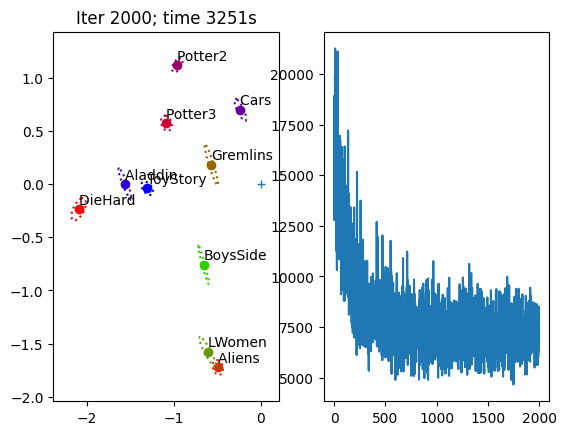

In [97]:
random.seed(seed)   # set seeds here to ensure consistency in your training process
pyro.set_rng_seed(seed)

tic = time.time()
loss = np.zeros(2000) + np.nan;

options = {"lr": 0.02 }
optimizer = pyro.optim.Adam(options)
svi = pyro.infer.SVI(model, guide, optimizer, loss=pyro.infer.Trace_ELBO(num_particles=10))

n,m = Xtr.shape

for step in range(2000): 
    loss[step] = svi.step(ratings,n,m,2,5)  
    
    if (step%10 == 9):
        clear_output(wait=True); plt.subplot(1,2,1); plt.plot(0,0,'+');  # clear plot, mark origin for visualization

        movie_means = [pyro.param(f'_V{j}').detach().numpy() for j in range(m)]
        movie_covs  = [pyro.param(f'_L{j}').detach().numpy() for j in range(m)]
        draw_gaussians(movie_means,movie_covs, labels=short); 

        ax=plt.axis(); plt.axis(np.array(ax)+[-.1,.1,-.1,.1]); plt.title(f'Iter {step+1}; time {int(time.time()-tic)}s')
        plt.subplot(1,2,2); plt.plot(loss);
        print(f'Train MSE: {predict(ratings,n,m,2)}; Test MSE {predict(rtest,n,m,2)}')
        plt.show()

**(b)** Training process output:

<div>
    <img src="data:image/svg+xml,%3C%3Fxml%20version%3D%221.0%22%20encoding%3D%22UTF-8%22%20standalone%3D%22no%22%3F%3E%0A%3C%21DOCTYPE%20svg%20PUBLIC%20%22-//W3C//DTD%20SVG%201.1//EN%22%20%22http%3A//www.w3.org/Graphics/SVG/1.1/DTD/svg11.dtd%22%3E%0A%3Csvg%20stroke-miterlimit%3D%2210%22%20style%3D%22fill-rule%3Anonzero%3Bclip-rule%3Aevenodd%3Bstroke-linecap%3Around%3Bstroke-linejoin%3Around%3B%22%20version%3D%221.1%22%20viewBox%3D%220%200%20288%2072%22%20xml%3Aspace%3D%22preserve%22%20xmlns%3D%22http%3A//www.w3.org/2000/svg%22%20xmlns%3Axlink%3D%22http%3A//www.w3.org/1999/xlink%22%3E%0A%3Cdefs/%3E%0A%3Cg%20id%3D%22Layer-1%22%3E%0A%3Cpath%20d%3D%22M34.042%2035.8741C45.8469%2023.244%2031.1794%2022.6473%2024.2857%2024.1167C17.3921%2025.5861-0.960215%2033.2987%206.07817%2043.4256C13.1166%2053.5525%2023.0237%2056.9377%2052.2446%2053.4091C81.4656%2049.8804%2097.2436%2032.811%20122.962%2029.3111C148.681%2025.8112%20155.118%2039.4093%20155.118%2039.4093%22%20fill%3D%22none%22%20opacity%3D%221%22%20stroke%3D%22%23000000%22%20stroke-linecap%3D%22butt%22%20stroke-linejoin%3D%22round%22%20stroke-width%3D%223%22/%3E%0A%3Cpath%20d%3D%22M254.053%2040.6889C242.328%2053.1071%20256.999%2053.6247%20263.883%2052.1549C270.768%2050.685%20289.071%2043.0512%20281.969%2033.1691C274.868%2023.287%20264.94%2020.0179%20235.741%2023.6051C206.543%2027.1922%20190.872%2043.9744%20165.176%2047.5176C139.48%2051.0607%20132.957%2037.7776%20132.957%2037.7776%22%20fill%3D%22none%22%20opacity%3D%221%22%20stroke%3D%22%23000000%22%20stroke-linecap%3D%22butt%22%20stroke-linejoin%3D%22round%22%20stroke-width%3D%223%22/%3E%0A%3C/g%3E%0A%3C/svg%3E%0A" width="200"/>
</div>

### [NOTE] If you are unable to finish training your model...

... you may use a pre-trained solution provided to finish the remainder of the homework instead, at a small penalty.  (This pre-trained solution is found using different model and guide initializations, in order to be distinguishable from the results you should find using your own training process.)

If you would like to load a pre-trained model, you can do so with the following cell:

In [59]:
LOAD_EXAMPLE_RESULTS = False

if LOAD_EXAMPLE_RESULTS:
    pyro.get_param_store().clear()          # clear all parameters, so we can re-initialize them here
    with open('cs179-hw5-params.pkl','rb') as fh:                # load the results as numpy arrays
        ubias,mbias,mmeans,mcovs,umeans,ucovs = pickle.load(fh)
    for j in range(m):
        pyro.param(f'_mu{j}',lambda: torch.tensor(mbias[j]))  # and re-initialize all parameters
        pyro.param(f'_V{j}', lambda: torch.tensor(mmeans[j]))
        pyro.param(f'_L{j}', lambda: torch.tensor(mcovs[j]))
    for i in range(n):
        pyro.param(f'_nu{i}', lambda: torch.tensor(ubias[i]))
        pyro.param(f'_U{i}',lambda: torch.tensor(umeans[i]))
        pyro.param(f'_S{i}',lambda: torch.tensor(ucovs[i]))  

On the other hand, if you have trained a model and wish to save it so you can re-load it later without re-training, you can do that as well, using the following cell:

In [98]:
SAVE_MY_RESULTS = True

if SAVE_MY_RESULTS:        # extract the pyro parameters to numpy arrays and write them to a file:
    import pickle 
    
    user_bias  = np.stack(tuple(pyro.param(f'_nu{i}').detach().numpy() for i in range(n)),axis=0)
    movie_bias = np.stack(tuple(pyro.param(f'_mu{j}').detach().numpy() for j in range(m)),axis=0)
    movie_means = np.stack(tuple(pyro.param(f'_V{j}').detach().numpy() for j in range(m)),axis=0)
    movie_covs  = np.stack(tuple(pyro.param(f'_L{j}').detach().numpy() for j in range(m)),axis=0)
    user_means = np.stack(tuple(pyro.param(f'_U{i}').detach().numpy() for i in range(n)),axis=0)
    user_covs  = np.stack(tuple(pyro.param(f'_S{i}').detach().numpy() for i in range(n)),axis=0)
    
    with open('cs179-hw5-params.pkl','wb') as fh:
        pickle.dump( (user_bias,movie_bias,movie_means,movie_covs,user_means,user_covs), fh)

**(c)**
* **Please say explicitly** whether you have used the provided parameter results, or your own from Part 3

I used my own.

<div>
    <img src="data:image/svg+xml,%3C%3Fxml%20version%3D%221.0%22%20encoding%3D%22UTF-8%22%20standalone%3D%22no%22%3F%3E%0A%3C%21DOCTYPE%20svg%20PUBLIC%20%22-//W3C//DTD%20SVG%201.1//EN%22%20%22http%3A//www.w3.org/Graphics/SVG/1.1/DTD/svg11.dtd%22%3E%0A%3Csvg%20stroke-miterlimit%3D%2210%22%20style%3D%22fill-rule%3Anonzero%3Bclip-rule%3Aevenodd%3Bstroke-linecap%3Around%3Bstroke-linejoin%3Around%3B%22%20version%3D%221.1%22%20viewBox%3D%220%200%20288%2072%22%20xml%3Aspace%3D%22preserve%22%20xmlns%3D%22http%3A//www.w3.org/2000/svg%22%20xmlns%3Axlink%3D%22http%3A//www.w3.org/1999/xlink%22%3E%0A%3Cdefs/%3E%0A%3Cg%20id%3D%22Layer-1%22%3E%0A%3Cpath%20d%3D%22M34.042%2035.8741C45.8469%2023.244%2031.1794%2022.6473%2024.2857%2024.1167C17.3921%2025.5861-0.960215%2033.2987%206.07817%2043.4256C13.1166%2053.5525%2023.0237%2056.9377%2052.2446%2053.4091C81.4656%2049.8804%2097.2436%2032.811%20122.962%2029.3111C148.681%2025.8112%20155.118%2039.4093%20155.118%2039.4093%22%20fill%3D%22none%22%20opacity%3D%221%22%20stroke%3D%22%23000000%22%20stroke-linecap%3D%22butt%22%20stroke-linejoin%3D%22round%22%20stroke-width%3D%223%22/%3E%0A%3Cpath%20d%3D%22M254.053%2040.6889C242.328%2053.1071%20256.999%2053.6247%20263.883%2052.1549C270.768%2050.685%20289.071%2043.0512%20281.969%2033.1691C274.868%2023.287%20264.94%2020.0179%20235.741%2023.6051C206.543%2027.1922%20190.872%2043.9744%20165.176%2047.5176C139.48%2051.0607%20132.957%2037.7776%20132.957%2037.7776%22%20fill%3D%22none%22%20opacity%3D%221%22%20stroke%3D%22%23000000%22%20stroke-linecap%3D%22butt%22%20stroke-linejoin%3D%22round%22%20stroke-width%3D%223%22/%3E%0A%3C/g%3E%0A%3C/svg%3E%0A" width="200"/>
</div>

### Part 4: Visualizing the Estimated Posterior

One of the advantages of a probabilistic model is our ability to gauge our uncertainty in our
estimates.  We will specifically examine three individual users, $i\in \{0,40,80\}$.

**(a)**
* Re-plot your movies' estimated posterior means and variances (the same Gaussian ellipses suggested
during optimization).  You should find that similar movies are located "nearby", meaning, in the same
direction from the origin $(0,0)$ as one another (since we measure ratings through dot products).
* For the selected users, also plot the **users'** posterior mean and uncertainty on the 
same plot as the movies.

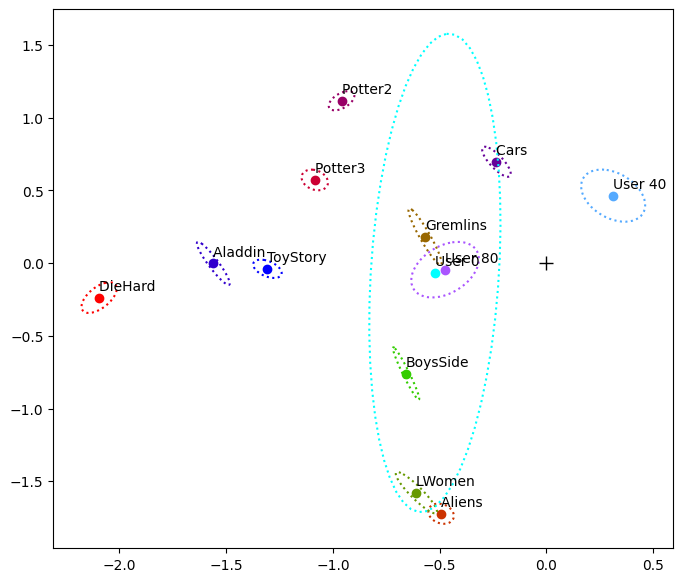

In [99]:
from matplotlib import colormaps

fig, ax = plt.subplots(figsize=(8,7))
ax.plot(0, 0, '+', ms=10, color='k')  # mark origin


movie_means = [pyro.param(f'_V{j}').detach().numpy() for j in range(m)]
movie_covs = [pyro.param(f'_L{j}').detach().numpy() for j in range(m)]
short_list = [short[j] for j in range(m)]
draw_gaussians(movie_means, movie_covs, labels=short_list)


ucmap = colormaps['cool']
ucolors = [ucmap(i/3) for i in range(3)]
user_ids = [0, 40, 80]
user_means_sel = [pyro.param(f'_U{i}').detach().numpy() for i in user_ids]
user_covs_sel = [pyro.param(f'_S{i}').detach().numpy() for i in user_ids]
ulabels = [f'User {i}' for i in user_ids]
draw_gaussians(user_means_sel, user_covs_sel, colors=ucolors, labels=ulabels)
plt.show()

**(b)**
* Next, **display** (print out) the training data (ratings) we used for three specific users.  
* How does your estimated uncertainty about the users' representation (the covariance) compare to that for the movies?  Why do you think this is?
* Which user has the largest covariance (highest uncertainty)?  Why?  Are the users' means and uncertainties (displayed in your previous plot) consistent with the training ratings?

In [100]:
for i in [0, 40, 80]:
    user_ratings = {j: v for (u,j),v in ratings.items() if u==i}
    cov = pyro.param(f'_S{i}').detach().numpy()
    print(f"User {i}: ratings={user_ratings}")
    print(f"Covariance:\n{cov}")
    print(f"det={np.linalg.det(cov):.4f}, trace={np.trace(cov):.4f}\n")

User 0: ratings={1: np.float64(0.64)}
Covariance:
[[0.02363867 0.02678041]
 [0.02678041 0.67707974]]
det=0.0153, trace=0.7007

User 40: ratings={0: np.float64(-0.36), 1: np.float64(-1.36), 3: np.float64(0.64), 4: np.float64(0.64), 5: np.float64(-0.36), 6: np.float64(-1.36), 8: np.float64(-0.36), 9: np.float64(0.64)}
Covariance:
[[ 0.00562682 -0.00244354]
 [-0.00244354  0.00804725]]
det=0.0000, trace=0.0137

User 80: ratings={0: np.float64(0.64), 1: np.float64(-0.36), 2: np.float64(-1.36), 3: np.float64(-0.36), 4: np.float64(-1.36), 5: np.float64(2.64), 6: np.float64(1.64), 8: np.float64(-2.36)}
Covariance:
[[0.00627738 0.00290193]
 [0.00290193 0.0091363 ]]
det=0.0000, trace=0.0154



Users tend to have larger covariances than movies because each movie is rated by many users but one user rates only a few movies (less evidence means posterior stays closer to the prior so higher uncertainty).

The user with fewest ratings will have the largest covariance (ellipse in plot bigger), since there is little data to constrain their latent position. Their ellipse in the plot will be larger, and their mean will be closer to the origin (pulled toward the prior).

### Part 5: Evaluating predictions

Having optimized our approximation $q$ to the posterior, we can use samples from $q$ to answer queries about the posterior model.  We can draw samples from $q$ by calling ``guide``, e.g.,

``nu,mu,U,V = guide({},n,m,2)``

**(a)**
* Draw 100 (approximate) posterior samples from your variational model $q$, similar to the prior samples you used in Part 2.
* Similarly to Part 2, plot a scatterplot of the training data for Die Hard ($i=5$) versus Aliens ($i=6$), again adding a small amount of noise.  Add to your plot a scatterplot of the average rating (over samples) for each user on those two movies, using the variational posterior samples you just generated. Color the points to distinguish them from your training data.
* How do your optimized posterior samples compare to the training data distribution?

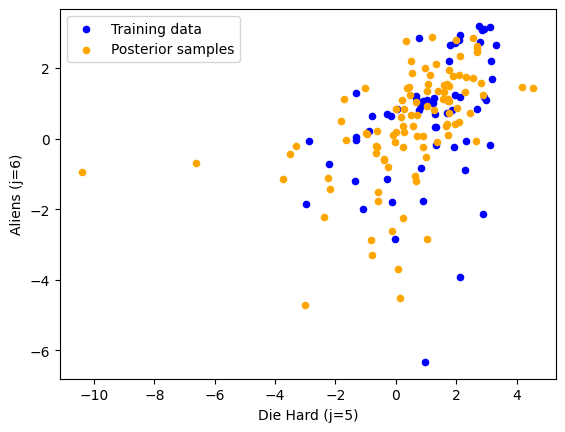

In [102]:
post_samples = np.stack(tuple(U@V.T+nu+mu.T for nu,mu,U,V in [guide({},n,m,2)]), axis=-1)

np.random.seed(seed)
plt.scatter(Xtr[:,5] + 0.7*np.random.rand(n), Xtr[:,6] + 0.7*np.random.rand(n), color='blue', label='Training data', s=20)
plt.scatter(post_samples[:,5,:].flatten(), post_samples[:,6,:].flatten(), color='orange', label='Posterior samples', s=20)
plt.xlabel('Die Hard (j=5)')
plt.ylabel('Aliens (j=6)')
plt.legend()
plt.show()

The posterior samples (orange) are more spread out than the prior samples were, and seem to follow the training data's general pattern more. The positive correlation between a user rating Die Hard high and Aliens high is captured. 

**(b)**
* Now, let's see how well we predict ratings for the users.  Plot a scatterplot of the true rating (x-axis) versus your predicted rating (y-axis) for Die Hard ($j=5$) on the training data.  Add to the plot a scatterplot of the same thing, but using the test data, colored in red.

* Are your model's predictions of the ratings in these two data sets predictive of their true rating?  Comment.

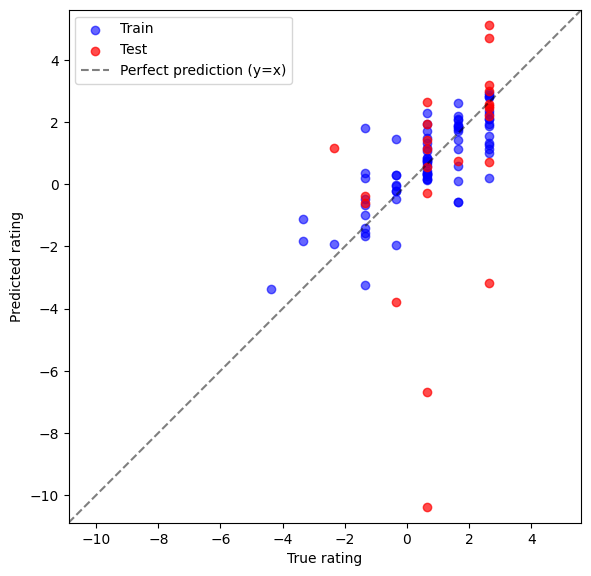

In [103]:
j_movie = 5  # Die Hard
def get_preds_for_movie(ratings_dict, j, n, m, k):
    nu_bar = np.stack([pyro.param(f'_nu{i}').detach().numpy() for i in range(n)])
    mu_bar = pyro.param(f'_mu{j}').detach().numpy().item()
    U_bar = np.stack([pyro.param(f'_U{i}').detach().numpy() for i in range(n)])
    V_bar = pyro.param(f'_V{j}').detach().numpy()
    true_r, pred_r = [], []
    for (i, jj), r in ratings_dict.items():
        if jj == j:
            rhat = nu_bar[i].item() + mu_bar + U_bar[i] @ V_bar
            true_r.append(r); pred_r.append(rhat)
    return np.array(true_r), np.array(pred_r)

tr_true, tr_pred = get_preds_for_movie(ratings, j_movie, n, m, 2)
te_true, te_pred = get_preds_for_movie(rtest, j_movie, n, m, 2)

fig, ax = plt.subplots(figsize=(6,6))
ax.scatter(tr_true, tr_pred, alpha=0.6, color='blue', label='Train')
ax.scatter(te_true, te_pred, alpha=0.7, color='red', label='Test')

lo = min(tr_true.min(), te_true.min(), tr_pred.min(), te_pred.min()) - 0.5
hi = max(tr_true.max(), te_true.max(), tr_pred.max(), te_pred.max()) + 0.5
ax.plot([lo, hi], [lo, hi], 'k--', alpha=0.5, label='Perfect prediction (y=x)')
ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
ax.set_aspect('equal')

ax.set_xlabel('True rating')
ax.set_ylabel('Predicted rating')
ax.legend()
plt.tight_layout()
plt.show()

The model's predictions are predictive of the true ratings. The predictions along the diagonals indicate perfect. As expected the model matches the training data much better, with there being some red points far from the diagonal. 

<div>
    <img src="data:image/svg+xml,%3C%3Fxml%20version%3D%221.0%22%20encoding%3D%22UTF-8%22%20standalone%3D%22no%22%3F%3E%0A%3C%21DOCTYPE%20svg%20PUBLIC%20%22-//W3C//DTD%20SVG%201.1//EN%22%20%22http%3A//www.w3.org/Graphics/SVG/1.1/DTD/svg11.dtd%22%3E%0A%3Csvg%20stroke-miterlimit%3D%2210%22%20style%3D%22fill-rule%3Anonzero%3Bclip-rule%3Aevenodd%3Bstroke-linecap%3Around%3Bstroke-linejoin%3Around%3B%22%20version%3D%221.1%22%20viewBox%3D%220%200%20288%2072%22%20xml%3Aspace%3D%22preserve%22%20xmlns%3D%22http%3A//www.w3.org/2000/svg%22%20xmlns%3Axlink%3D%22http%3A//www.w3.org/1999/xlink%22%3E%0A%3Cdefs/%3E%0A%3Cg%20id%3D%22Layer-1%22%3E%0A%3Cpath%20d%3D%22M34.042%2035.8741C45.8469%2023.244%2031.1794%2022.6473%2024.2857%2024.1167C17.3921%2025.5861-0.960215%2033.2987%206.07817%2043.4256C13.1166%2053.5525%2023.0237%2056.9377%2052.2446%2053.4091C81.4656%2049.8804%2097.2436%2032.811%20122.962%2029.3111C148.681%2025.8112%20155.118%2039.4093%20155.118%2039.4093%22%20fill%3D%22none%22%20opacity%3D%221%22%20stroke%3D%22%23000000%22%20stroke-linecap%3D%22butt%22%20stroke-linejoin%3D%22round%22%20stroke-width%3D%223%22/%3E%0A%3Cpath%20d%3D%22M254.053%2040.6889C242.328%2053.1071%20256.999%2053.6247%20263.883%2052.1549C270.768%2050.685%20289.071%2043.0512%20281.969%2033.1691C274.868%2023.287%20264.94%2020.0179%20235.741%2023.6051C206.543%2027.1922%20190.872%2043.9744%20165.176%2047.5176C139.48%2051.0607%20132.957%2037.7776%20132.957%2037.7776%22%20fill%3D%22none%22%20opacity%3D%221%22%20stroke%3D%22%23000000%22%20stroke-linecap%3D%22butt%22%20stroke-linejoin%3D%22round%22%20stroke-width%3D%223%22/%3E%0A%3C/g%3E%0A%3C/svg%3E%0A" width="200"/>
</div>

### Statement of Collaboration (5 points)

It is **mandatory** to include a Statement of Collaboration in each submission, with respect to the guidelines below. Include the names of everyone involved in the discussions (especially in-person ones), and what was discussed.

All students are required to follow the academic honesty guidelines posted on the course website. For
programming assignments, in particular, I encourage the students to organize (perhaps using EdD) to
discuss the task descriptions, requirements, bugs in my code, and the relevant technical content before they start
working on it. However, you should not discuss the specific solutions, and, as a guiding principle, you are not
allowed to take anything written or drawn away from these discussions (i.e. no photographs of the blackboard,
written notes, referring to EdD, etc.). Especially after you have started working on the assignment, try
to restrict the discussion to EdD as much as possible, so that there is no doubt as to the extent of your
collaboration.

no collaboration